# 10. Systems of ODEs

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

In the previous chapter we used Euler’s method and `ode45` to solve a single first-order differential equation. In this chapter, we’ll move on to systems of ODEs and implement a model of a predator-prey system. But first, we have to learn more about matrices.

## Matrices

A *matrix* is a two-dimensional version of a vector. Like a vector, it contains elements that are identified by indices. The difference is that the elements are arranged in rows and columns, so it takes *two* indices to identify an element.

### Creating a Matrix

A common way to create a matrix is the `zeros` function, which returns a matrix with the given size filled with zeros. This example creates a matrix with two rows and three columns.

In [2]:
M = zeros(2, 3)

M =

   0   0   0
   0   0   0



If you don’t know the size of a matrix, you can display it by using `whos`:

In [3]:
whos M

Variables visible from the current scope:

variables in scope: top scope

  Attr   Name        Size                     Bytes  Class
  ====   ====        ====                     =====  ===== 
         M           2x3                         48  double

Total is 6 elements using 48 bytes



or the `size` function, which returns a vector:

In [4]:
V = size(M)

V =

   2   3



The first element is the number of rows; the second is the number of columns.

To read an element of a matrix, you specify the row and column numbers:

In [5]:
M(1,2)
M(2,3)

ans = 0


ans = 0


When you’re working with matrices, it takes some effort to remember which index comes first, row or column. I find it useful to repeat “row, column” to myself, like a mantra. You might also find it helpful to remember “down, across” or the abbreviation RC as in “radio control” or RC Cola.

Another way to create a matrix is to enclose the elements in brackets, with semicolons between rows:

In [6]:
D = [1,2,3 ; 4,5,6]
size(D)

D =

   1   2   3
   4   5   6



ans =

   2   3



### Row and Column Vectors

Although it’s useful to think in terms of numbers, vectors, and matrices, from MATLAB’s point of view everything is a matrix. A number is just a matrix that happens to have one row and one column:

In [7]:
x = 5;
size(x)

ans =

   1   1



And a vector is a matrix with only one row:

In [8]:
R = 1:5;
size(R)

ans =

   1   5



Well, some vectors have only one row, anyway. Actually, there are two kinds of vectors. The ones we’ve seen so far are called *row vectors*, because the elements are arranged in a row; the other kind are *column vectors*, where the elements are in a single column.

One way to create a column vector is to create a matrix with only one element per row:

In [9]:
C = [1;2;3]
size(C)

C =

   1
   2
   3



ans =

   3   1



The difference between row and column vectors is important in linear algebra, but for most basic vector operations, it doesn’t matter. For example, when you index the elements of a vector, you don’t have to know what kind it is:

In [10]:
R(2)
C(2)

ans = 2


ans = 2


### The Transpose Operator

The transpose operator, which looks remarkably like an apostrophe, computes the *transpose* of a matrix, which is a new matrix that has all of the elements of the original, but with each row transformed into a column (or you can think of it the other way around).

In this example `D` has two rows:

In [11]:
D = [1,2,3 ; 4,5,6]

D =

   1   2   3
   4   5   6



so its transpose has two columns:

In [12]:
Dt = D'

Dt =

   1   4
   2   5
   3   6



**Exercise 10.1.** What effect does the transpose operator have on row vectors, column vectors, and numbers?

## Solving Systems of ODEs

Now that we’ve seen the basics of matrices, let’s see how we can use them to solve systems of differential equations.

### Lotka-Volterra

The Lotka-Volterra model describes the interactions between two species in an ecosystem, a predator and its prey. As an example, we’ll consider foxes and rabbits.

The model is governed by the following system of differential equations:

$$\begin{aligned}
    \frac{dx}{dt} &= a x - b x y         \\
    \frac{dy}{dt} &= -c y + d x y
\end{aligned}$$

where $x$ and $y$ are the populations of rabbits and foxes, and $a$, $b$, $c$, and $d$ are parameters that quantify the interactions between the two species (see <https://greenteapress.com/matlab/lotka>).

At first glance, you might think you could solve these equations by calling `ode45` once to solve for $x$ and once to solve for $y$. The problem is that each equation involves both variables, which is what makes this a *system of equations* and not just a list of unrelated equations. To solve a system, you have to solve the equations simultaneously.

Fortunately, `ode45` can handle systems of equations. The difference is that the initial condition is a vector that contains the initial values $x(0)$ and $y(0)$, and the output is a matrix that contains one column for $x$ and one for $y$.

Listing 10.1 shows the rate function with the parameters $a = 0.1$, $b = 0.01$, $c = 0.1$, and $d = 0.002$:

*Listing 10.1: A rate function for Lotka-Volterra*

In [13]:
function res = rate_func(t, V)
    % unpack the elements of V
    x = V(1);
    y = V(2);

    % set the parameters
    a = 0.1;
    b = 0.01;
    c = 0.1;
    d = 0.002;

    % compute the derivatives
    dxdt = a*x - b*x*y;
    dydt = -c*y + d*x*y;

    % pack the derivatives into a vector
    res = [dxdt; dydt];
end

The first input variable, `t`, is time. Even though the time variable is not used in this rate function, it has to be there in order for this function to work with `ode45`. The second input variable, `V`, is a vector with two elements, $x(t)$ and $y(t)$. The body of the function includes four sections, each explained by a comment.

The first section *unpacks* the vector by copying the elements into variables. This isn’t necessary, but giving names to these values will help you to remember what’s what. It also makes the third section, where we compute the derivatives, resemble the mathematical equations we were given, which helps prevent errors.

The second section sets the parameters that describe the reproductive rates of rabbits and foxes, and the characteristics of their interactions. If we were studying a real system, these values would come from observations of real animals, but for this example I chose values that yield interesting results.

The third section computes the derivatives of $x$ and $y$, using the equations we were given.

The last section *packs* the computed derivatives back into a vector. When `ode45` calls this function, it provides a vector as input and expects to get a vector as output.

Sharp-eyed readers will notice something different about this line:

```
res = [dxdt; dydt];
```

The semicolon between the elements of the vector is not an error. It is necessary in this case because `ode45` requires the result of this function to be a column vector.

As always, it’s a good idea to test your rate function before you call `ode45`. Create a file named *lotka.m* with the following top-level function:

In [14]:
function res = lotka()
    t = 0;
    V_init = [80, 20];
    rate_func(t, V_init)
end

In [15]:
lotka

ans =

  -8.0000
   1.2000



`V_init` is a vector that represents the initial condition, 80 rabbits and 20 foxes. The result from `rate_func` is

which means that with these initial conditions, we expect the rabbit population to decline initially at a rate of 8 per week and the fox population to increase by 1.2 per week.

Now we can run `ode45` like this:

In [16]:
V_init = [80, 20];    % the initial condition, as in lotka
tspan = [0, 200]
[T, M] = ode45(@rate_func, tspan, V_init)

tspan =

     0   200



T =

          0
     0.0170
     0.0341
     0.0511
     0.0681
     0.0937
     0.1192
     0.1448
     0.1703
     0.2086
     0.2470
     0.2853
     0.3236
     0.3811
     0.4386
     0.4961
     0.5535
     0.6398
     0.7260
     0.8122
     0.8985
     1.0278
     1.1571
     1.2865
     1.4158
     1.6098
     1.8038
     1.9978
     2.1918
     2.4829
     2.7739
     3.0649
     3.3559
     3.7924
     4.2289
     4.6655
     5.1020
     5.7568
     6.4115
     7.0663
     7.7211
     8.7033
     9.6854
    10.6676
    11.6498
    13.1230
    14.5963
    16.0695
    17.5428
    19.2904
    21.0379
    22.7855
    24.5331
    26.8107
    29.0882
    31.3658
    33.6433
    37.0597
    40.4760
    43.8923
    47.3087
    49.9493
    52.5900
    55.2306
    57.8713
    59.5048
    61.1383
    62.7718
    64.4053
    66.2290
    68.0527
    69.8764
    71.7001
    73.5292
    75.3583
    77.1874
    79.0165
    80.9966
    82.9768
    84.9569
    86.9371
    88.7553
    90.5735

The first argument is the function handle for the rate function. The second argument is the time span, from 0 to 200 weeks. The third argument is the initial condition.

### Output Matrices

The `ode45` function returns two values: `T`, a vector, and `M`, a matrix.

In [17]:
size(T)
size(M)

ans =

   125     1



ans =

   125     2



`T` has 101 rows and 1 column, so it is a column vector with one row for each time step.

`M` has 101 rows, one for each time step, and 2 columns, one for each variable, $x$ and $y$.

This structure—one column per variable—is a common way to use matrices. And `plot` understands this structure, so if you do the following:

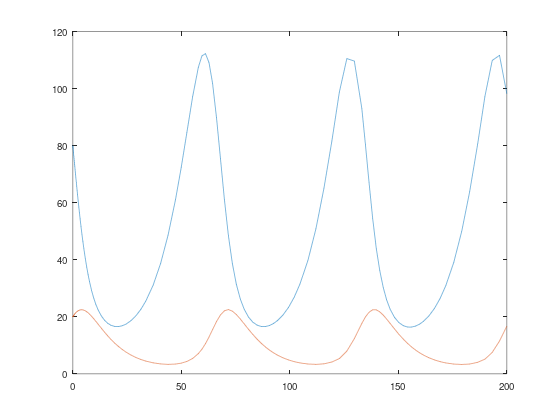

In [18]:
plot(T, M)

MATLAB understands that it should plot each column from `M` versus `T`.

You can copy the columns of `M` into other variables like this:

In [19]:
R = M(:, 1);
F = M(:, 2);

In this context, the colon represents the range from `1` to `end`, so `M(:, 1)` means “all the rows, column 1” and `M(:, 2)` means “all the rows, column 2.”

In [20]:
size(R)
size(F)

ans =

   125     1



ans =

   125     1



So `R` and `F` are column vectors.

Now we can plot these vectors separately, which makes it easier to give them different style strings:

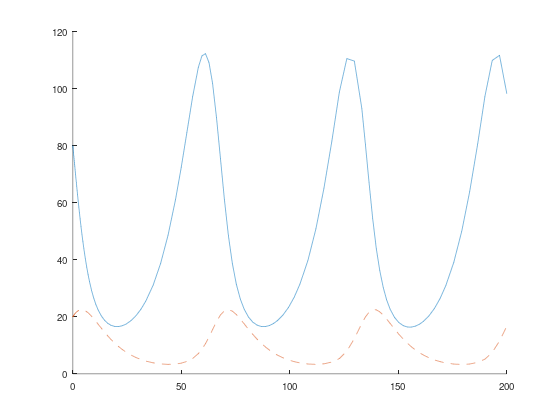

In [21]:
hold on
plot(T, R, '-')
plot(T, F, '--')

Figure 10.1 shows the results. The x-axis is time in weeks; the y-axis is population. The top curve shows the population of rabbits; the bottom curve shows foxes.

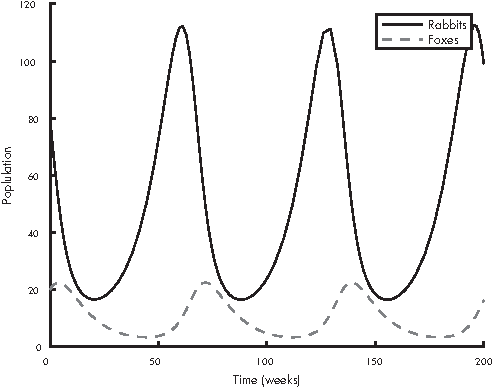

*Figure 10.1: Solution for the Lotka-Volterra model*

Initially, there are too many foxes, so the rabbit population declines. Then there are not enough rabbits, and the fox population declines. That allows the rabbit population to recover, and the pattern repeats.

This cycle of “boom and bust” is typical of the Lotka-Volterra model.

### Phase Plot

Instead of plotting the two populations over time, it is sometimes useful to plot them against each other:

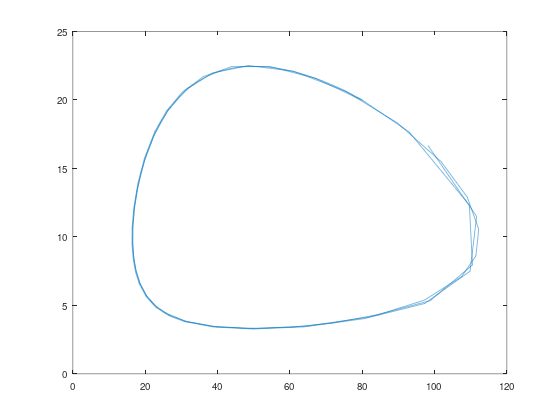

In [22]:
plot(R, F)

Figure 10.2 shows the result, which is called a *phase plot*. Each point on this plot represents a certain number of rabbits (on the x-axis) and a certain number of foxes (on the y-axis). Since these are the only two variables in the system, each point in this plane describes the complete *state* of the system, that is, the values of the variables we’re solving for.

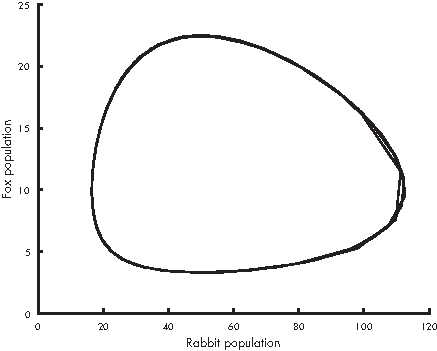

*Figure 10.2: Phase plot from the Lotka-Volterra model*

Over time, the state moves around the plane. Figure 10.2 shows the path traced by the state over time; this path is called a *trajectory*.

Since the behavior of this system is periodic, the trajectory is a loop.

If there are three variables in the system, we need three dimensions to show the state of the system, so the trajectory is a 3D curve. You can use `plot3` to trace trajectories in three dimensions, but for four or more variables, you’re on your own.

### What Could Go Wrong?

The output vector from the rate function has to be a column vector, otherwise you get an error:

In MATLAB, the error message is:

```
Error using odearguments (line 93)
RATE_FUNC must return a column vector.
```

*In Octave, `ode45` accepts a rate function that returns a row vector, so you don't get this error; but return a column vector anyway, so your code works in MATLAB.*

which is a pretty good error message. It’s not clear *why* it needs to be a column vector, but that’s not our problem.

Another possible error is reversing the order of the elements in the initial conditions or the vectors inside `lotka`. MATLAB doesn’t know what the elements are supposed to mean, so it can’t catch errors like this; it will just produce incorrect results.

The order of the elements (rabbits and foxes) is up to you, but you have to be consistent. That is, the order of the initial conditions you provide when you call `ode45` has to be the same as the order inside `rate_func` where you unpack the input vector and the same as the order of the derivatives in the output vector.

## Chapter Review

In this chapter, we used `ode45` to solve a system of first-order differential equations. As an exercise, you’ll have a chance to solve the famous Lorenz equations, one of the first examples of a chaotic system.

Here are the terms from this chapter you might want to remember.

A *row vector* is a matrix that has only one row, and a *column vector* is a matrix that has only one column. The *transpose operation* transforms the rows of a matrix into columns (or the other way around, if you prefer).

A *system of equations* is a collection of equations written in terms of the same set of variables.

In a rate function, we often have to *unpack* the input variable, copying the elements of a vector into a set of variables. Then we have to *pack* the results into a vector as an output variable.

The *state* of a system is a set of variables that quantify the condition of the system as it changes over time.

When we solve a system of differential equations, we can visualize the results with a *phase plot*, which shows the state of a system as a point in the space of possible states. A *trajectory* is a path in a phase plot that shows how the state of a system changes over time.

In the next chapter, we’ll move on to second-order systems, which we use to describe systems with objects moving in space, governed by Newton’s laws of motion.

## Exercises

Before you go on, you might want to work on the following exercise.

**Exercise 10.2.**

Based on the examples we’ve seen so far, you’d think that all ODEs describe population as a function of time, but that’s not true.

For example, the Lorenz system is a system of differential equations based on a model of fluid dynamics in the atmosphere (see <https://greenteapress.com/matlab/lorenz>). It turns out to be interesting in part because its solutions are chaotic; that is, small changes in the initial conditions yield big differences in the solutions.

The system is described by these differential equations:

$$\begin{aligned}
x_t &= \sigma (y - x)  \\
y_t &= x (r - z) - y   \\
z_t &= xy - b z
\end{aligned}$$

Common values for the parameters are $\sigma = 10$, $b = 8/3$, and $r=28$.

Use `ode45` to estimate a solution to this system of equations.

1.  Create a file named *lorenz.m* with a top-level function named `lorenz` and a helper function named `rate_func`.

2.  The rate function should take `t` and `V` as input variables, where the components of `V` are understood to be the current values of `x`, `y`, and `z`. It should compute the corresponding derivatives and return them in a single column vector.

3.  Test the function by calling it from the top-level function with values like $t=0$, $x=1$, $y=2$, and $z=3$. Once you get your function working, you should make it a silent function before calling `ode45`.

4.  Use `ode45` to estimate the solution for the time span $[0, 30]$ with the initial condition $x=1$, $y=2$, and $z=3$.

5.  Plot the results as a time series, that is, each of the variables as a function of time.

6.  Use `plot3` to plot the trajectory of $x$, $y$, and $z$.

In [23]:
% Exercise 10.1 (the transpose operator): your solution here


In [24]:
% Solution

% Solve the Lorentz system and plot the results.

function res = lorenz()
    % Run the ode solver
    [T, M] = ode45(@rate_func, [0 30], [1 2 3]);

    % plot the results
    X = M(:,1);
    Y = M(:,2);
    Z = M(:,3);
    plot3(X, Y, Z)
    xlabel('X')
    ylabel('Y')
    zlabel('Z')

    % uncomment this to see the trajectory animated
    % comet3(X, Y, Z);
end

function res = rate_func(t, V)
    % unpack the state vector
    x = V(1);
    y = V(2);
    z = V(3);

    % set the parameters
    sigma = 10;
    b = 8/3;
    r = 28;

    % compute the derivatives
    dxdt = sigma * (y-x);
    dydt = x * (r-z) - y;
    dzdt = x*y - b*z;

    % pack the results in a column vector
    res = [dxdt; dydt; dzdt];
end

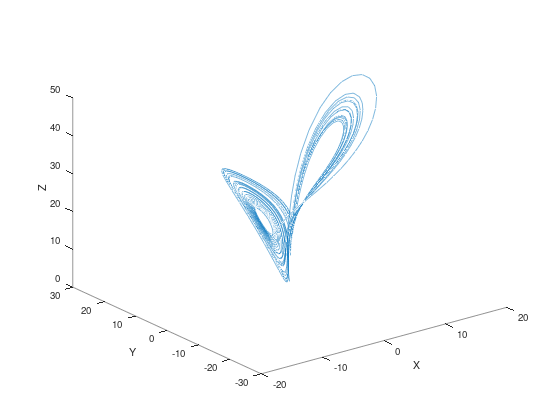

In [25]:
% Solution

lorenz